# Iron-Deficiency Anemia Screening from Routine Blood Counts
Research notebook: data exploration, leakage control, and model prototyping (Decision Tree vs SVM).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, classification_report)
sns.set_theme(style='whitegrid')

## 1. Load data

In [2]:
df = pd.read_csv('data/anemia_dataset.csv')
df = df.rename(columns={'NE#':'NEUT','LY#':'LYMPH','MO#':'MONO','EO#':'EOS','BA#':'BASO','FERRITTE':'FERRITIN',
    'SD':'SERUM_IRON','SDTSD':'TIBC','TSD':'TRANSFERRIN_SAT','Iron_anemia_Class':'IRON_CLASS',
    'HGB_Anemia_Class':'HGB_CLASS','Folate_anemia_class':'FOLATE_CLASS','B12_Anemia_class':'B12_CLASS','All_Class':'ALL_CLASS'})
df['Iron_Status'] = np.where(df.IRON_CLASS==1,'Iron Deficient','Normal')
print('Shape:', df.shape)
display(df.head())
print('Missing values:', df.isnull().sum().sum(), '| duplicate rows:', df.duplicated().sum())
print(df.IRON_CLASS.value_counts(normalize=True).round(3))

Shape: (15300, 30)


,GENDER,WBC,NEUT,LYMPH,MONO,EOS,BASO,RBC,HGB,HCT,...,TRANSFERRIN_SAT,FERRITIN,FOLATE,B12,ALL_CLASS,HGB_CLASS,IRON_CLASS,FOLATE_CLASS,B12_CLASS,Iron_Status
0,1,10.63,6.31,2.79,0.91,0.56,0.06,4.31,12.7,37.6,...,40.176778,194.00,5.06,178.2,4,0,0,0,1,Normal
1,1,5.08,2.50,1.87,0.43,0.26,0.02,4.34,12.8,36.9,...,33.482553,57.37,9.88,197.7,4,0,0,0,1,Normal
2,1,13.68,9.40,2.69,1.55,0.03,0.01,3.18,9.4,27.5,...,20.144429,114.20,8.37,143.0,4,0,0,0,1,Normal
3,1,5.60,3.94,0.83,0.54,0.26,0.03,3.35,10.5,31.4,...,27.731559,214.20,6.39,139.9,4,0,0,0,1,Normal
4,1,3.57,2.03,1.25,0.10,0.18,0.01,1.31,5.1,14.3,...,78.860623,303.40,4.30,50.0,4,0,0,0,1,Normal


Missing values: 0 | duplicate rows: 88
IRON_CLASS
0    0.727
1    0.273
Name: proportion, dtype: float64


## 2. Leakage control
The iron panel (ferritin, serum iron, TIBC, transferrin saturation) defines the label, and the other `*_CLASS`, folate and B12 columns are separate targets/labs. Only CBC + sex are used.

In [3]:
CBC = ['WBC','NEUT','LYMPH','MONO','EOS','BASO','RBC','HGB','HCT','MCV','MCH','MCHC','RDW','PLT','MPV','PCT','PDW']
FEATURES = ['GENDER'] + CBC
X, y = df[FEATURES], df.IRON_CLASS
print(len(FEATURES), 'features used')

18 features used


## 3. Exploratory analysis

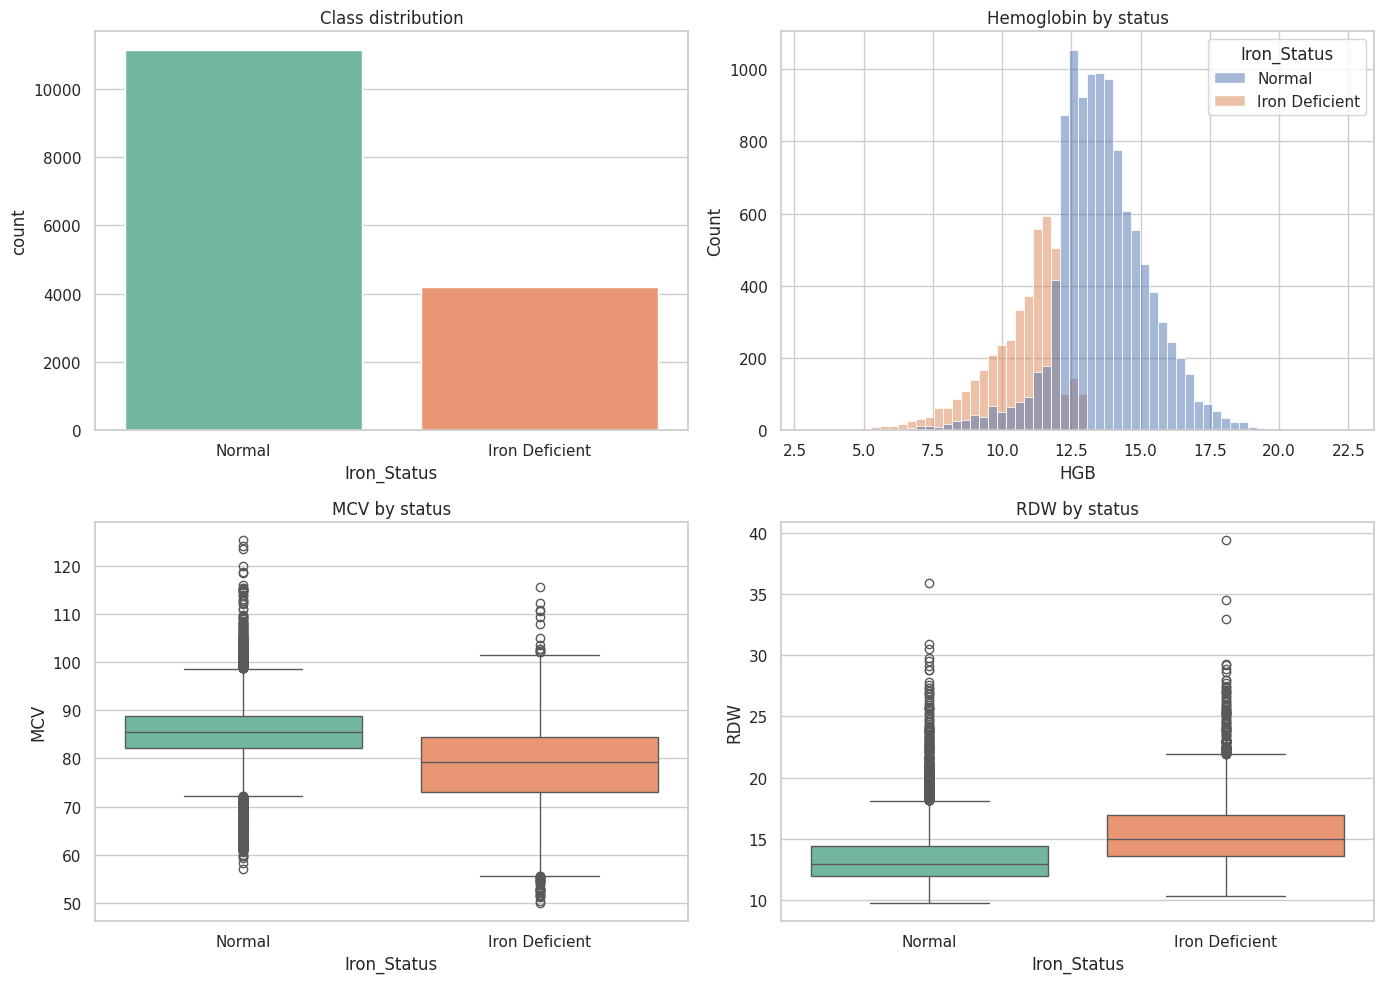

In [4]:
fig, ax = plt.subplots(2,2, figsize=(14,10))
sns.countplot(x='Iron_Status', data=df, ax=ax[0,0], palette='Set2'); ax[0,0].set_title('Class distribution')
sns.histplot(data=df, x='HGB', hue='Iron_Status', bins=60, ax=ax[0,1]); ax[0,1].set_title('Hemoglobin by status')
sns.boxplot(x='Iron_Status', y='MCV', data=df, ax=ax[1,0], palette='Set2'); ax[1,0].set_title('MCV by status')
sns.boxplot(x='Iron_Status', y='RDW', data=df, ax=ax[1,1], palette='Set2'); ax[1,1].set_title('RDW by status')
plt.tight_layout(); plt.show()

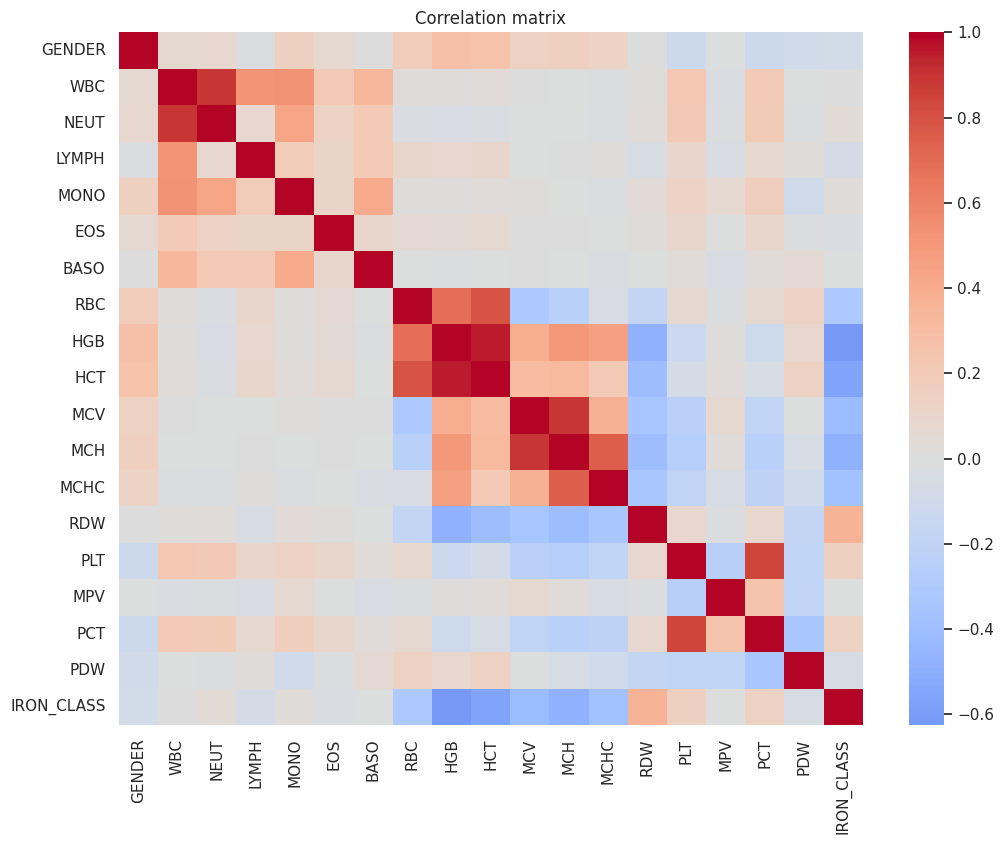

HGB      -0.626
HCT      -0.569
MCH      -0.474
MCV      -0.413
MCHC     -0.374
RBC      -0.315
GENDER   -0.081
LYMPH    -0.063
PDW      -0.050
EOS      -0.026
MPV      -0.009
BASO     -0.008
WBC       0.007
MONO      0.021
NEUT      0.042
PCT       0.142
PLT       0.152
RDW       0.363
Name: IRON_CLASS, dtype: float64


In [5]:
plt.figure(figsize=(12,9)); sns.heatmap(df[FEATURES+['IRON_CLASS']].corr(), cmap='coolwarm', center=0); plt.title('Correlation matrix'); plt.show()
print(df[FEATURES+['IRON_CLASS']].corr()['IRON_CLASS'].drop('IRON_CLASS').sort_values().round(3))

In [6]:
print(df.groupby('Iron_Status')[['HGB','MCV','MCH','RDW','FERRITIN']].median().round(2))
print('\nOutlier check (physiologically implausible extremes kept: clinically real cases):')
print(df[CBC].describe(percentiles=[.01,.99]).T[['min','1%','99%','max']].round(2))

                 HGB    MCV    MCH   RDW  FERRITIN
Iron_Status                                       
Iron Deficient  11.0  79.21  25.20  15.0     13.81
Normal          13.5  85.47  28.54  12.9     51.07

Outlier check (physiologically implausible extremes kept: clinically real cases):
         min     1%     99%      max
WBC     0.57   3.03   19.83   246.70
NEUT    0.03   1.42   15.59   197.20
LYMPH   0.11   0.53    4.78    89.60
MONO    0.00   0.17    1.40    18.51
EOS     0.00   0.00    0.72     9.41
BASO    0.00   0.01    0.18    24.73
RBC     0.87   2.84    6.31     7.50
HGB     2.99   7.20   17.62    22.45
HCT     7.21  23.87   51.98    67.40
MCV    49.93  60.97  100.20   125.30
MCH    12.55  17.31   33.60   139.00
MCHC   18.07  27.69   36.41   168.00
RDW     9.72  10.51   22.50    39.40
PLT    13.00  65.88  557.40  1770.00
MPV     3.62   5.49   13.43    19.60
PCT     0.01   0.06    0.47     1.63
PDW     7.30   8.80   23.58    25.00


## 4. Train / test split and scaling

In [7]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
sc = StandardScaler().fit(X_tr); X_tr_s, X_te_s = sc.transform(X_tr), sc.transform(X_te)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
print(X_tr.shape, X_te.shape)

(12240, 18) (3060, 18)


## 5. Models

In [8]:
dt  = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=42).fit(X_tr, y_tr)
svm = SVC(kernel='rbf', C=1.0, class_weight='balanced', probability=True, random_state=42).fit(X_tr_s, y_tr)

def evaluate(model, Xt, Xtr):
    p, pr = model.predict(Xt), model.predict_proba(Xt)[:,1]
    return {'Accuracy':accuracy_score(y_te,p),'Precision':precision_score(y_te,p),'Recall':recall_score(y_te,p),
            'F1':f1_score(y_te,p),'ROC-AUC':roc_auc_score(y_te,pr),
            'CV Accuracy':cross_val_score(model, Xtr, y_tr, cv=cv, scoring='accuracy').mean()}, p, pr

m_dt, p_dt, pr_dt = evaluate(dt, X_te, X_tr)
m_sv, p_sv, pr_sv = evaluate(SVC(kernel='rbf', C=1.0, class_weight='balanced', probability=True, random_state=42).fit(X_tr_s,y_tr), X_te_s, X_tr_s)
results = pd.DataFrame({'Decision Tree':m_dt,'SVM (RBF)':m_sv}).T.round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,CV Accuracy
Decision Tree,0.9163,0.7690,0.9916,0.8662,0.9715,0.9162
SVM (RBF),0.8974,0.7417,0.9581,0.8361,0.9632,0.9027


In [9]:
print('--- Decision Tree ---'); print(classification_report(y_te, p_dt, target_names=['Normal','Iron Deficient']))
print('--- SVM ---');           print(classification_report(y_te, p_sv, target_names=['Normal','Iron Deficient']))

--- Decision Tree ---
                precision    recall  f1-score   support

        Normal       1.00      0.89      0.94      2224
Iron Deficient       0.77      0.99      0.87       836

      accuracy                           0.92      3060
     macro avg       0.88      0.94      0.90      3060
  weighted avg       0.93      0.92      0.92      3060

--- SVM ---
                precision    recall  f1-score   support

        Normal       0.98      0.87      0.93      2224
Iron Deficient       0.74      0.96      0.84       836

      accuracy                           0.90      3060
     macro avg       0.86      0.92      0.88      3060
  weighted avg       0.92      0.90      0.90      3060



## 6. Confusion matrices and ROC

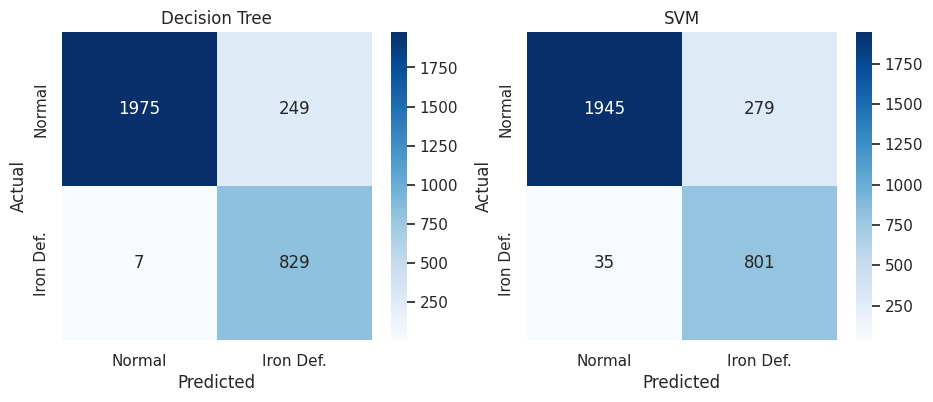

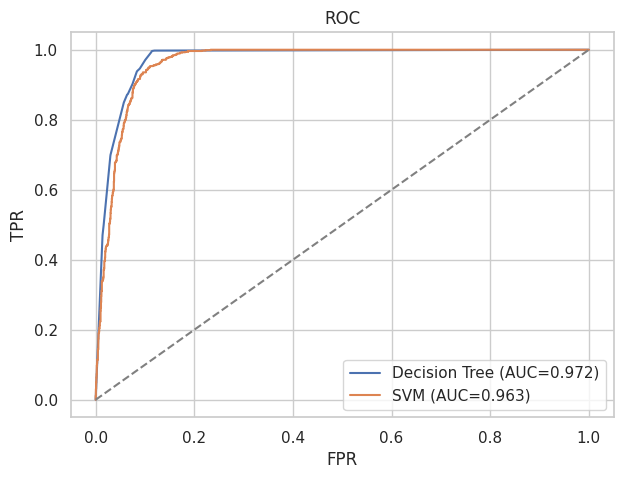

In [10]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
for a,(n,p) in zip(ax, [('Decision Tree',p_dt),('SVM',p_sv)]):
    sns.heatmap(confusion_matrix(y_te,p), annot=True, fmt='d', cmap='Blues', ax=a, xticklabels=['Normal','Iron Def.'], yticklabels=['Normal','Iron Def.'])
    a.set_title(n); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.show()
plt.figure(figsize=(7,5))
for n,pr in [('Decision Tree',pr_dt),('SVM',pr_sv)]:
    f,t,_ = roc_curve(y_te, pr); plt.plot(f,t,label=f'{n} (AUC={roc_auc_score(y_te,pr):.3f})')
plt.plot([0,1],[0,1],'--',c='grey'); plt.legend(); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC'); plt.show()

## 7. Interpretability

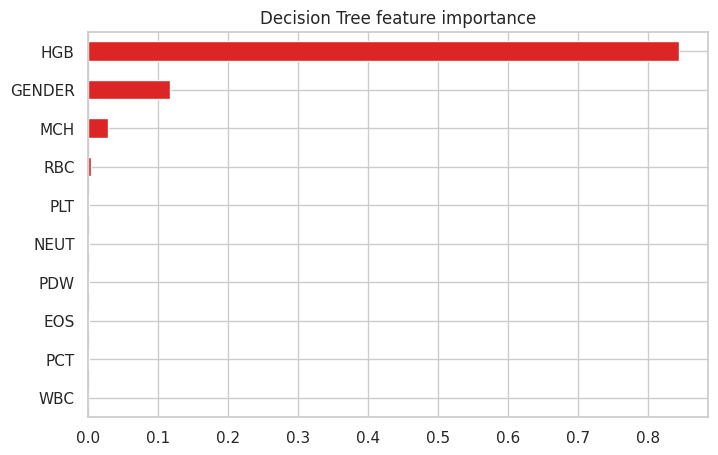

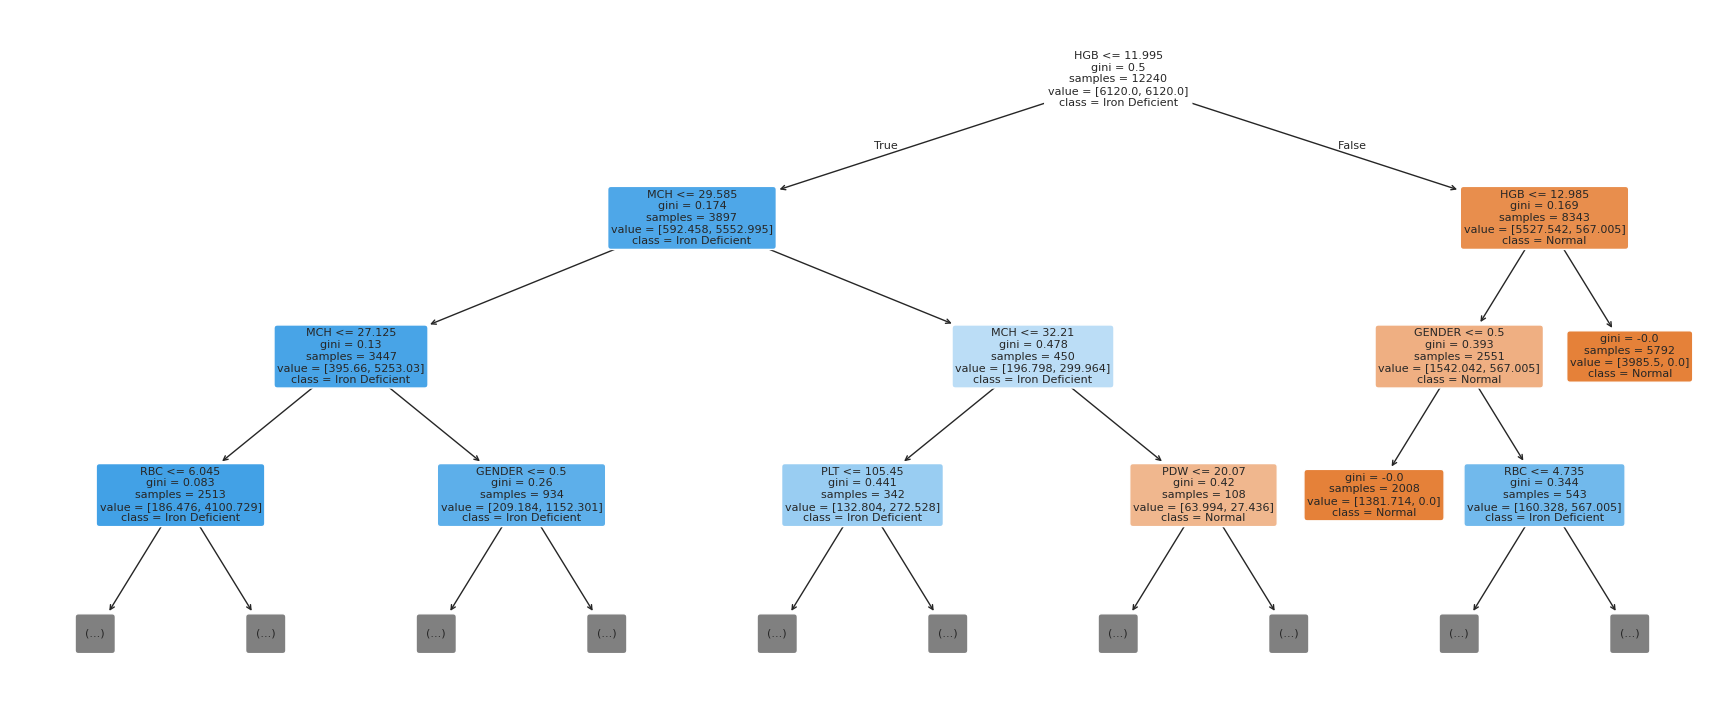

In [11]:
imp = pd.Series(dt.feature_importances_, index=FEATURES).sort_values(ascending=False)
imp.head(10).iloc[::-1].plot.barh(figsize=(8,5), color='#DC2626'); plt.title('Decision Tree feature importance'); plt.show()
plt.figure(figsize=(22,9)); plot_tree(dt, feature_names=FEATURES, class_names=['Normal','Iron Deficient'], filled=True, rounded=True, fontsize=8, max_depth=3); plt.show()

## 8. Conclusions
* Red-cell indices (HGB, MCV, MCH, RDW) carry most of the signal; a routine CBC can pre-screen for iron deficiency.
* Recall on the iron-deficient class is prioritised because a missed patient is costlier than an extra confirmatory ferritin test.
* The tree gives auditable rules; the SVM is the non-linear benchmark.
* Limitations: single-source data, labels derived from lab thresholds, no medication/diet/menstrual history. Not for clinical use.